Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

Load the dataset

In [2]:
# Load the original dataset
df = pd.read_csv("../data/Frogs_MFCCs.csv")

# Remove accidental whitespace around column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")

Dataset loaded successfully!


Inspect the dataset

In [3]:
print("Dataset shape:", df.shape)

print("\nFirst five observations:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (7195, 26)

First five observations:


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,MFCCs_11,MFCCs_12,MFCCs_13,MFCCs_14,MFCCs_15,MFCCs_16,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,0.188654,-0.075622,-0.156436,0.082245,0.135752,-0.024017,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,0.270958,-0.095004,-0.254341,0.022786,0.163320,0.012022,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,0.266064,-0.072827,-0.237384,0.050791,0.207338,0.083536,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,0.267279,-0.162258,-0.317084,-0.011567,0.100413,-0.050224,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,0.332695,-0.100749,-0.298524,0.037439,0.219153,0.062837,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Column names:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7195 entries, 0 to 7194
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   MFCCs_ 1  7195 non-null   float64
 1   MFCCs_ 2  7195 non-null   float64
 2   MFCCs_ 3  7195 non-null   float64
 3   MFCCs_ 4  7195 non-null   float64
 4   MFCCs_ 5  7195 non-null   float64
 5   MFCCs_ 6  7195 non-null   float64
 6   MFCCs_ 7  7195 non-null   float64
 7   MFCCs_ 8  7195 non-null   float64
 8   MFCCs_ 9  7195 non-null   float64
 9   MFCCs_10  7195 non-null   float64
 10  MFCCs_11  7195 non-null   float64
 11  MFCCs_12  7195 non-null   float64
 12  MFCCs_13 

Check missing and duplicate values

In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
MFCCs_ 1    0
MFCCs_ 2    0
MFCCs_ 3    0
MFCCs_ 4    0
MFCCs_ 5    0
MFCCs_ 6    0
MFCCs_ 7    0
MFCCs_ 8    0
MFCCs_ 9    0
MFCCs_10    0
MFCCs_11    0
MFCCs_12    0
MFCCs_13    0
MFCCs_14    0
MFCCs_15    0
MFCCs_16    0
MFCCs_17    0
MFCCs_18    0
MFCCs_19    0
MFCCs_20    0
MFCCs_21    0
MFCCs_22    0
Family      0
Genus       0
Species     0
RecordID    0
dtype: int64

Total missing values: 0

Duplicate rows: 0


Identify input and target columns

In [5]:
# Extract the 22 MFCC feature columns
feature_columns = [
    col for col in df.columns if col.startswith("MFCCs_")
]

# Select the target
target_column = "Species"

X = df[feature_columns]
y = df[target_column]

print("Number of input features:", len(feature_columns))
print("Number of observations:", len(df))
print("Number of species:", y.nunique())

print("\nSpecies:")
print(sorted(y.unique()))

Number of input features: 22
Number of observations: 7195
Number of species: 10

Species:
['AdenomeraAndre', 'AdenomeraHylaedactylus', 'Ameeregatrivittata', 'HylaMinuta', 'HypsiboasCinerascens', 'HypsiboasCordobae', 'LeptodactylusFuscus', 'OsteocephalusOophagus', 'Rhinellagranulosa', 'ScinaxRuber']


Examine class distribution

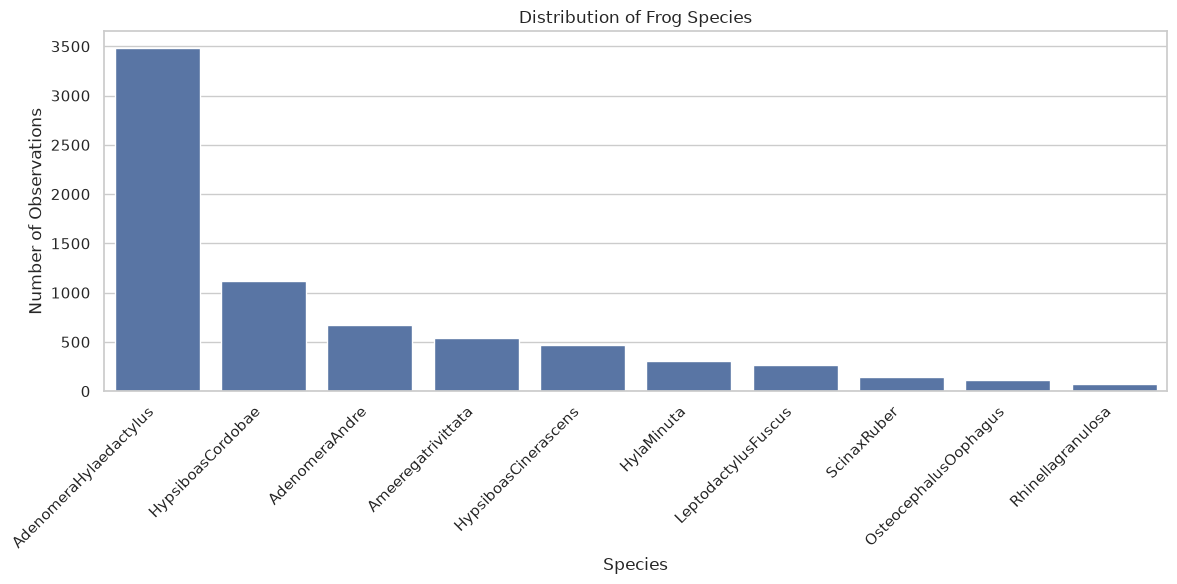

In [6]:
species_counts = df["Species"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=species_counts.index,
    y=species_counts.values
)

plt.title("Distribution of Frog Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Examine feature distributions

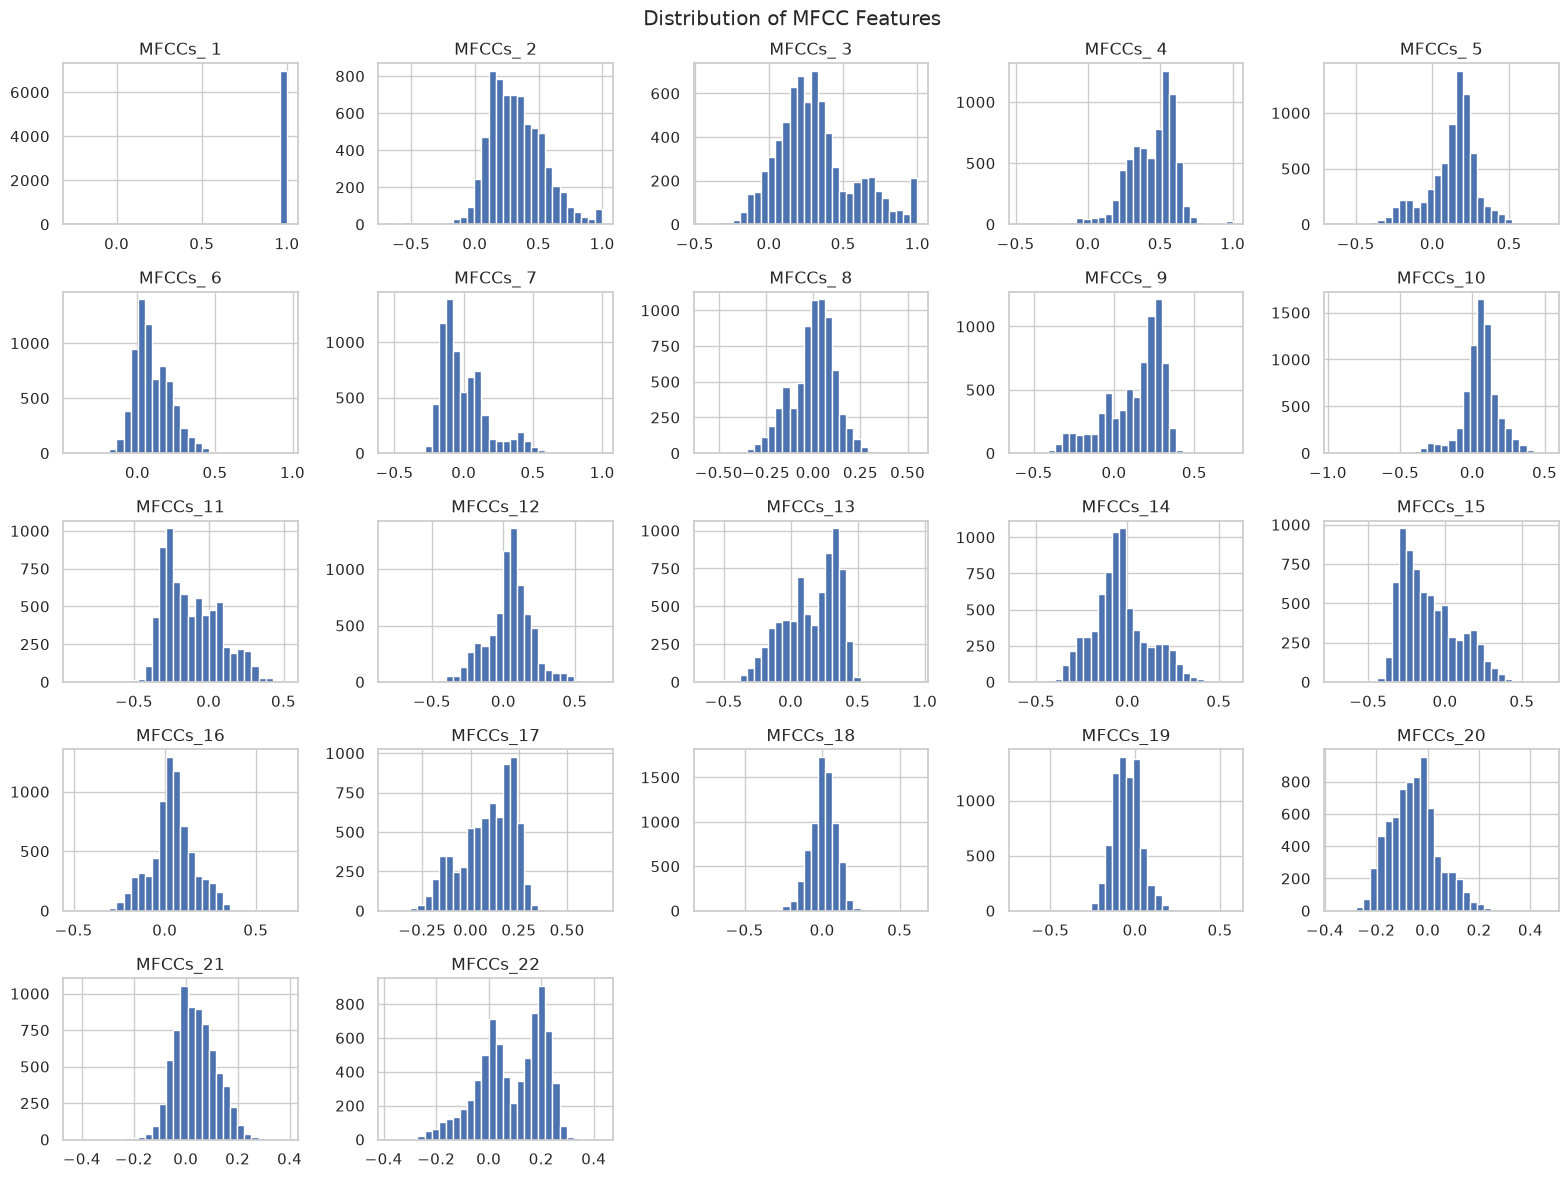

In [7]:
df[feature_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of MFCC Features")
plt.tight_layout()
plt.show()

Species distribution

In [8]:
species_summary = df.groupby("Species").agg(
    Number_of_Observations=("Species", "size"),
    Number_of_Recordings=("RecordID", "nunique")
).sort_values(
    by="Number_of_Observations",
    ascending=False
)

display(species_summary)

,Number_of_Observations,Number_of_Recordings
Species,,
AdenomeraHylaedactylus,3478,11
HypsiboasCordobae,1121,4
AdenomeraAndre,672,8
Ameeregatrivittata,542,5
HypsiboasCinerascens,472,4
HylaMinuta,310,11
LeptodactylusFuscus,270,4
ScinaxRuber,148,5
OsteocephalusOophagus,114,3


Visualize species distribution

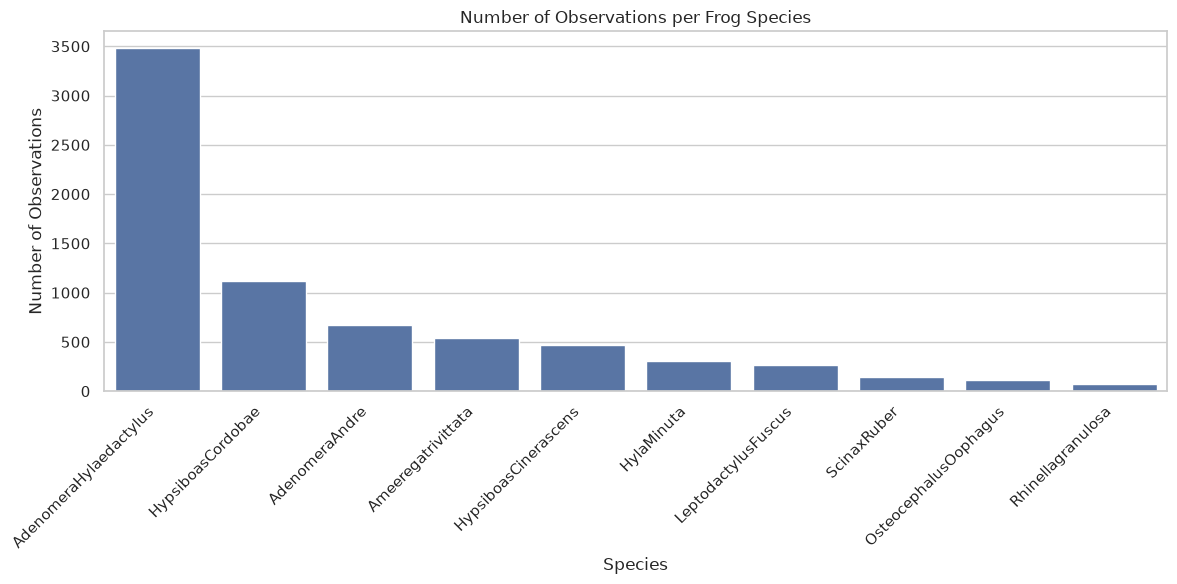

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=species_summary.reset_index(),
    x="Species",
    y="Number_of_Observations"
)

plt.title("Number of Observations per Frog Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Examine MFCC feature correlations

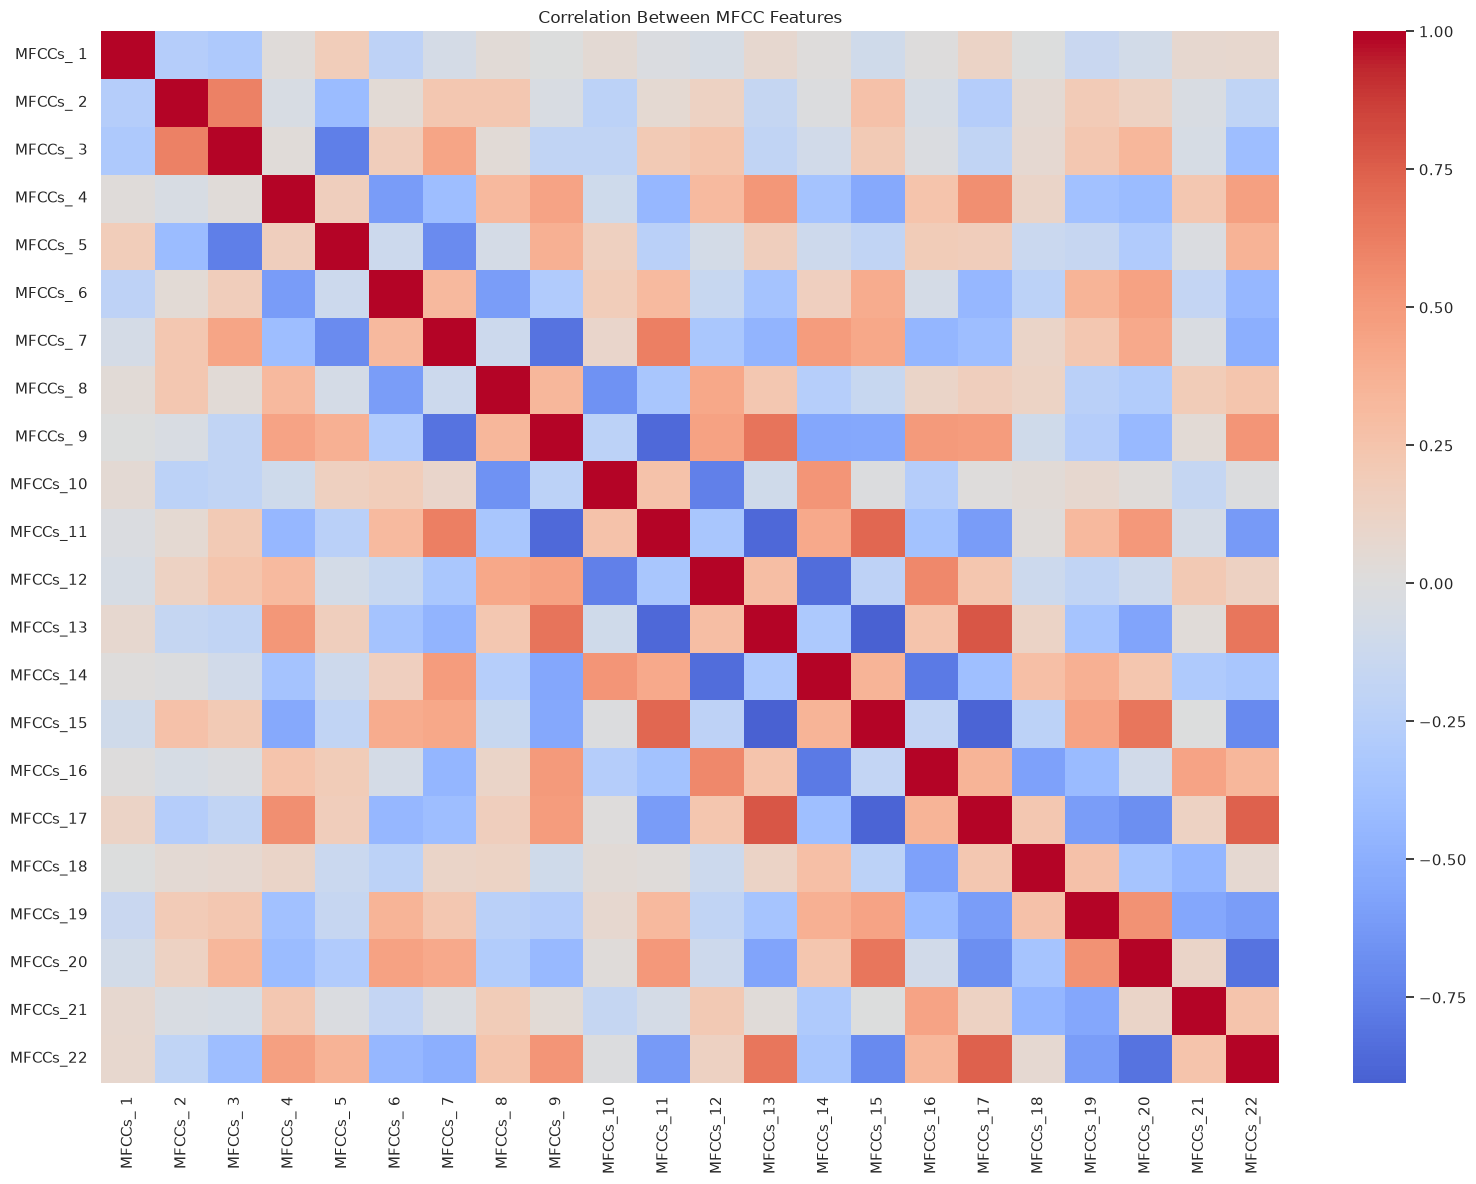

In [10]:
plt.figure(figsize=(16, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Between MFCC Features")
plt.tight_layout()
plt.show()

Find a suitable group-based split

In [17]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

X = df[feature_columns]
y = df["Species"]
groups = df["RecordID"]

all_species = sorted(y.unique())

# Original species proportions
original_distribution = (
    y.value_counts(normalize=True)
    .reindex(all_species)
)

splitter = GroupShuffleSplit(
    n_splits=5000,
    test_size=0.20,
    random_state=42
)

best_split = None
best_score = float("inf")

for train_idx, test_idx in splitter.split(X, y, groups):

    y_train_candidate = y.iloc[train_idx]
    y_test_candidate = y.iloc[test_idx]

    # Every species must appear in both sets
    if set(y_train_candidate.unique()) != set(all_species):
        continue

    if set(y_test_candidate.unique()) != set(all_species):
        continue

    # Calculate test-set class proportions
    test_distribution = (
        y_test_candidate.value_counts(normalize=True)
        .reindex(all_species, fill_value=0)
    )

    # Measure deviation from original proportions
    class_difference = np.abs(
        test_distribution - original_distribution
    ).sum()

    # Penalize splits far from 80:20
    size_difference = abs(
        len(test_idx) / len(df) - 0.20
    )

    score = class_difference + size_difference

    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx)

if best_split is None:
    raise ValueError("No suitable group split found.")

train_idx, test_idx = best_split

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

print("\nTest-set class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("\nCommon recordings:",
      len(train_groups.intersection(test_groups)))

Training observations: 5622
Testing observations: 1573

Training distribution:
Species
AdenomeraAndre             603
AdenomeraHylaedactylus    2725
Ameeregatrivittata         385
HylaMinuta                 271
HypsiboasCinerascens       327
HypsiboasCordobae          755
LeptodactylusFuscus        255
OsteocephalusOophagus      111
Rhinellagranulosa           60
ScinaxRuber                130
Name: count, dtype: int64

Testing distribution:
Species
AdenomeraAndre             69
AdenomeraHylaedactylus    753
Ameeregatrivittata        157
HylaMinuta                 39
HypsiboasCinerascens      145
HypsiboasCordobae         366
LeptodactylusFuscus        15
OsteocephalusOophagus       3
Rhinellagranulosa           8
ScinaxRuber                18
Name: count, dtype: int64

Test-set class proportions:
Species
AdenomeraAndre            0.043865
AdenomeraHylaedactylus    0.478703
Ameeregatrivittata        0.099809
HylaMinuta                0.024793
HypsiboasCinerascens      0.092181
Hypsiboa

Cell 22 — Check class representation

In [18]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nSpecies in training:", y_train.nunique())
print("Species in testing:", y_test.nunique())

Training class distribution:
Species
AdenomeraAndre             603
AdenomeraHylaedactylus    2725
Ameeregatrivittata         385
HylaMinuta                 271
HypsiboasCinerascens       327
HypsiboasCordobae          755
LeptodactylusFuscus        255
OsteocephalusOophagus      111
Rhinellagranulosa           60
ScinaxRuber                130
Name: count, dtype: int64

Testing class distribution:
Species
AdenomeraAndre             69
AdenomeraHylaedactylus    753
Ameeregatrivittata        157
HylaMinuta                 39
HypsiboasCinerascens      145
HypsiboasCordobae         366
LeptodactylusFuscus        15
OsteocephalusOophagus       3
Rhinellagranulosa           8
ScinaxRuber                18
Name: count, dtype: int64

Species in training: 10
Species in testing: 10


Verify there is no recording leakage

In [19]:
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Training recordings:", len(train_groups))
print("Testing recordings:", len(test_groups))

print(
    "Common recordings:",
    len(train_groups.intersection(test_groups))
)

assert len(train_groups.intersection(test_groups)) == 0
assert y_train.nunique() == 10
assert y_test.nunique() == 10

print("\nAll split validation checks passed!")

Training recordings: 48
Testing recordings: 12
Common recordings: 0

All split validation checks passed!


In [20]:
# Examine how many independent recordings belong to each species
recording_summary = df.groupby("Species").agg(
    Total_Observations=("Species", "size"),
    Number_of_Recordings=("RecordID", "nunique")
)

# Calculate the average number of observations per recording
recording_summary["Avg_Observations_Per_Recording"] = (
    recording_summary["Total_Observations"] /
    recording_summary["Number_of_Recordings"]
)

display(recording_summary.sort_values(
    by="Number_of_Recordings"
))

,Total_Observations,Number_of_Recordings,Avg_Observations_Per_Recording
Species,,,
OsteocephalusOophagus,114,3,38.000000
LeptodactylusFuscus,270,4,67.500000
HypsiboasCinerascens,472,4,118.000000
HypsiboasCordobae,1121,4,280.250000
Ameeregatrivittata,542,5,108.400000
Rhinellagranulosa,68,5,13.600000
ScinaxRuber,148,5,29.600000
AdenomeraAndre,672,8,84.000000
AdenomeraHylaedactylus,3478,11,316.181818
